# 03 · Why these features?

**The question.** The model decides from the movement which hand made it. Why these features,
and how were they found?

**The short answer.** They were not found by trying many features and keeping the best. They
follow from one argument, made before the first model was trained (14 Nov): a left-hand movement
is roughly the **mirror image** of a right-hand one. A mirror tells exactly which sensor channels
must change sign between the hands and which must stay the same. The features are simple
numbers (net turn, largest rate, mean) from the channels that must change sign.

**Chronology, honestly.** On 13 Nov the first look at the data (notebook 01, right vs left
profiles) already showed the clearest difference in one rotation channel; on 14 Nov the real
rotation axes were found (D-51): it is the turn about the phone's long axis. The 9 features and
the rules (D-40 – D-51) were fixed before the first model run. The checks in sections 2–5 below
were made afterwards (15 Nov): they do not show how the features were found, they test whether
the argument behind them holds on all the data.

This notebook uses the same movements as the model (rules D-41 – D-52, see notebook 02) and
shows people only anonymously.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis" / "loading.py").exists())
sys.path.insert(0, str(ROOT / "analysis"))

import matplotlib.pyplot as plt
import pandas as pd

import feature_check as fc
from features import features_table
from loading import export_info, load_raw
from model import select_study_trials
from plots import apply_style

apply_style()
pd.set_option("display.width", 160)

raw_sessions, raw_trials = load_raw()
feats = features_table(raw_sessions, raw_trials)
data, left_out = select_study_trials(feats)
signals = fc.reach_signals(raw_sessions, raw_trials, data)
print("Export made:", export_info().get("exported_at", "?"))
print(f"Used: {data['session_id'].nunique()} people, {len(data)} movements to the nose")

Export made: 2026-11-14T16:43:32+00:00
Used: 22 people, 257 movements to the nose


## 1. The prediction from mirror symmetry

The phone is upright in the palm, screen to the face. Its axes: **x** across the screen
(sideways), **y** along the phone (up), **z** out of the screen towards the face. Mirroring a
movement at the person's midline reverses **x**. Acceleration is an ordinary vector, so only its
x component changes sign. Rotation is an axial vector (it follows the right-hand rule), so under
the same mirror the rotation about x keeps its sign and the rotations about y and z change sign.

| channel | under the mirror | so between the hands it should |
|---|---|---|
| acceleration x (sideways) | changes sign | **differ** |
| rotation about y (turn about the long axis) | changes sign | **differ** |
| rotation about z (turn in the screen plane) | changes sign | **differ** |
| acceleration y (along the phone) | same | be the same |
| acceleration z (towards the face) | same | be the same |
| rotation about x (tilt towards the face) | same | be the same |

This is a prediction that can fail: if a "same" channel differed strongly, or a "differ"
channel did not differ at all, the argument would be wrong.

## 2. The prediction, checked at every moment of the movement

Every movement is put on the same time axis (0 = high beep, 1 = nose touch). At each moment and
for each channel the colour shows how well that one value separates the hands: blue = the right
hand has higher values, orange = the left hand, light = no difference. The value is the chance
that a random right-hand movement has a higher value than a random left-hand movement
(0.5 = no difference, 1 or 0 = the hands never overlap).

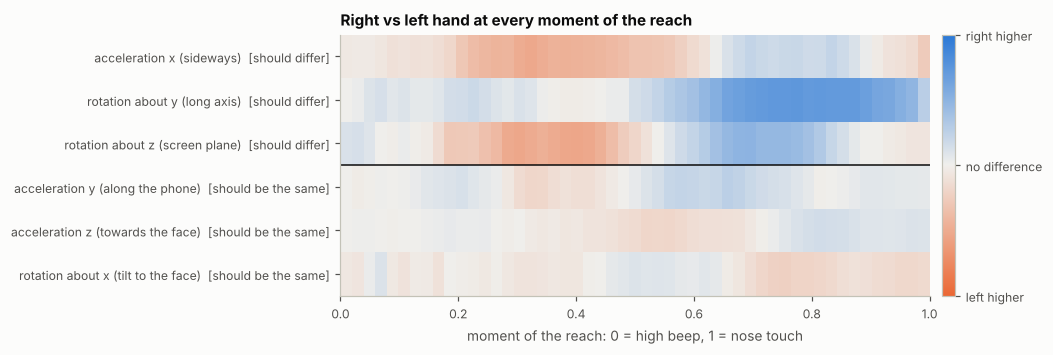

In [2]:
sep = fc.separation_over_time(signals, data)
fig = fc.plot_separation_map(sep)
plt.show()

**What it shows (data of 14 Nov):** the three channels above the line, the ones that should
differ, are the ones with colour. Rotation about the long axis is strongly blue in the second half
of the reach. Rotation in the screen plane is orange first and blue later: it changes direction
during the movement, so its net turn is almost the same for both hands, while its peaks differ.
Sideways acceleration differs a little in the middle of the reach. The three channels below the
line, the ones that should be the same, stay pale.

## 3. The features on the signal

One right-hand and one left-hand movement of the same person, on the exact signals the features
are computed from (even 50 Hz grid, smoothed, real axes). The person is not hand-picked: it is the
adult whose own difference between the hands is closest to the median of all people, and for each
hand the movement closest to that person's median.

- **net turn** = the shaded area under the rotation curve during the reach (degrees);
- **max / min** = the circles, the fastest turn in each direction (deg/s);
- **mean** = the dashed line, the average sideways acceleration (minus its value before the beep).

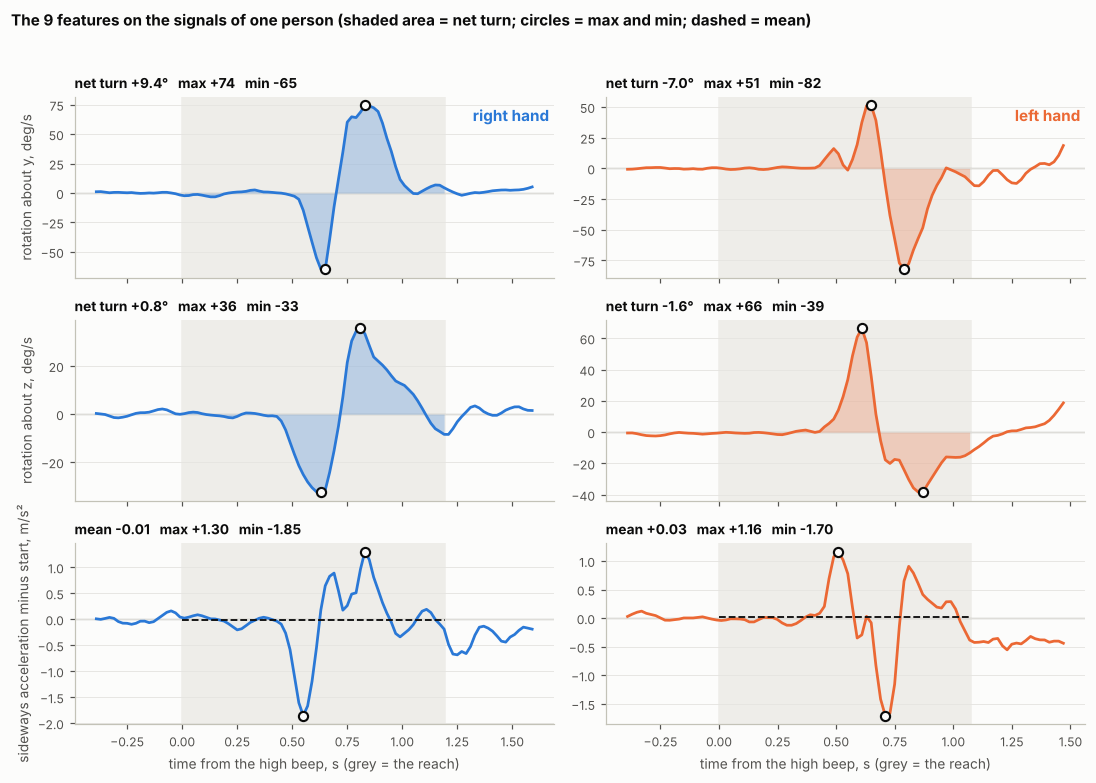

In [3]:
person = fc.typical_person(data)
fig = fc.plot_features_on_signal(raw_sessions, raw_trials, data, person)
plt.show()

The two hands draw nearly mirror-image curves: where the right hand turns the phone one way,
the left hand turns it the other way. The larger, later turn decides the sign of the net turn.

## 4. Every movement of every person

The turn about the long axis for all movements, one small panel per person (anonymous, sorted
from the clearest difference to the weakest). "sign rule" = in how many of this person's
movements the sign of the net turn alone gives the right answer (negative = left hand).

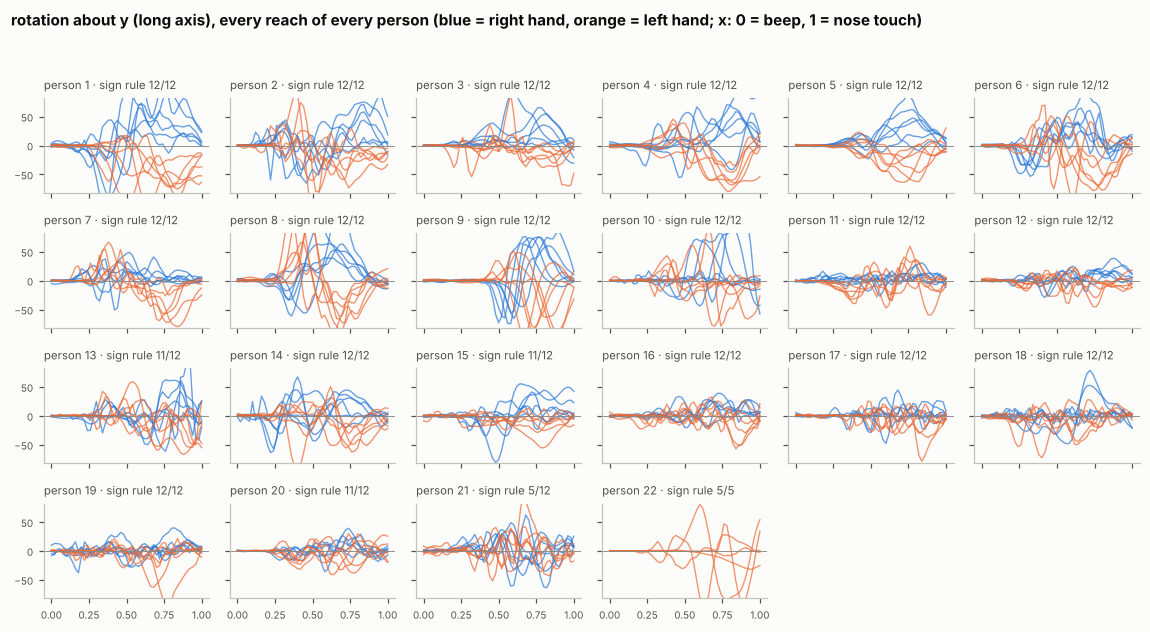

In [4]:
fig = fc.plot_people_grid(signals, data, "rot_y")
plt.show()

Most people separate their hands the same way. The exceptions are visible directly: a person
who turns the phone the same way with both hands, and a person with movements of one hand only
(the other hand's movements were dropped by D-52, the phone did not move).

## 5. A wider check: all simple candidates from all six channels

To make sure nothing better was missed, four simple numbers were computed from **each** of the
six channels over the reach (24 candidates, computed like `features.py`): for rotation the net
turn, mean, largest and smallest rate; for acceleration (minus its value before the beep) the
mean, largest, smallest and the change at the end. Blue bars come from channels that should
differ, grey bars from channels that should be the same; ◆ marks the 9 features of `features.py`.

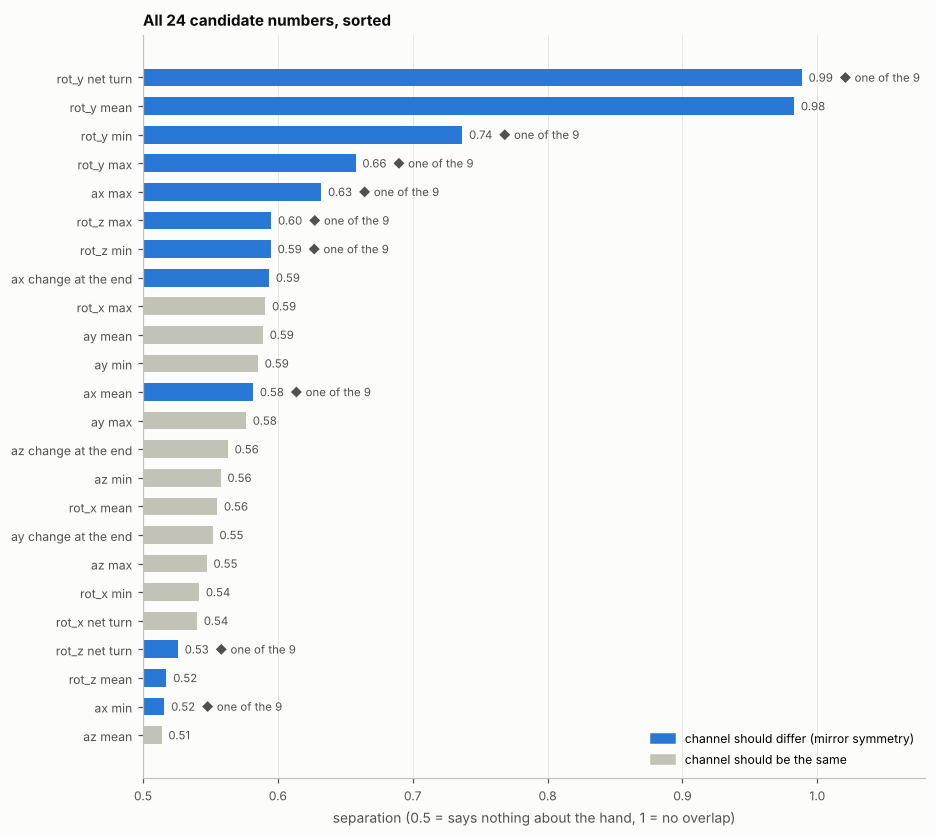

,channel,mirror symmetry says,one of the 9 features,separation,"people, same direction"
candidate,,,,,
rot_y net turn,rotation about y (long axis),should differ,yes,0.99,21 / 21
rot_y mean,rotation about y (long axis),should differ,,0.98,21 / 21
rot_y min,rotation about y (long axis),should differ,yes,0.74,19 / 21
rot_y max,rotation about y (long axis),should differ,yes,0.66,16 / 21
ax max,acceleration x (sideways),should differ,yes,0.63,15 / 21
rot_z max,rotation about z (screen plane),should differ,yes,0.60,14 / 21
rot_z min,rotation about z (screen plane),should differ,yes,0.59,17 / 21
ax change at the end,acceleration x (sideways),should differ,,0.59,13 / 21
rot_x max,rotation about x (tilt to the face),should be the same,,0.59,14 / 21


In [5]:
cands = fc.candidate_features(raw_sessions, raw_trials, data)
screen = fc.screen_table(cands, data)
fig = fc.plot_screen(screen)
plt.show()
screen.round(2)

**What it shows:** the top of the list is the turn about the long axis (net turn, and its
mean rate, which is the same information divided by the duration). No candidate from a channel
that should be the same separates the hands better than about 0.6, close to chance. So the
search over all channels finds what the symmetry argument predicted, and nothing better.

A caveat: this check was made after the model, and with 24 candidates the best one could look
good by chance. A separation of 0.99 with the same direction in every person is far beyond that.

## 6. In short: why these features

1. **Theory first.** A left-hand movement is the mirror image of a right-hand one; the mirror
   predicts that only sideways acceleration and the rotations about y and z differ (section 1).
2. **The prediction holds on all the data.** These three channels carry the difference, the
   other three do not (section 2), and a search over all channels finds nothing better (section 5).
3. **The strongest one is easy to explain.** The phone turns about its long axis in opposite
   directions for the two hands (section 3), in almost every person (section 4). That is why the
   final model uses this one feature.
4. **Limits.** People who turn the phone the same way with both hands, and a different grip,
   are not covered.